# 04 - Customer segmentation and retention drivers

**Questions:** (Q5) Which customer segments generate the most value? (Q6) What predicts whether a customer ever comes back?

Data comes from the PostgreSQL views built in Phases 2-3: `vw_customer_summary`, `vw_cohort_retention`, `vw_first_order_profile`.
Run `sql/03_analysis/run_all.sql` and `sql/03_analysis/08_first_purchase_drivers.sql` first. The connection string is read from the `DATABASE_URL` environment variable.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src import segmentation as sg

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
engine = sg.get_engine()
pd.options.display.float_format = '{:,.2f}'.format

## 1. RFM segmentation

- **Recency** and **Monetary** are scored in quintiles (5 = best). Snapshot date: 2018-09-01.
- **Frequency is not scored in quintiles.** 97% of customers placed exactly one order, so quintiles would just be noise. Repeat buying is an explicit rule instead: 2+ orders.
- Customer = `customer_unique_id`. Revenue = `SUM(price)` over valid sales, all time.

In [2]:
seg = sg.build_segments(engine)
print(f"{len(seg):,} customers | {seg.revenue.sum():,.0f} R$ lifetime revenue | {(seg.orders>=2).mean():.1%} repeat buyers\n")
print("Recency quintiles (days since last order):")
print(seg.groupby('R').recency_days.agg(['min','max']).round(0).sort_index(ascending=False).T.to_string())
print("\nMonetary quintiles (R$ lifetime spend):")
print(seg.groupby('M').revenue.agg(['min','max']).round(0).T.to_string())
summary = sg.segment_summary(seg)
summary

94,982 customers | 13,494,111 R$ lifetime revenue | 3.0% repeat buyers

Recency quintiles (days since last order):
R       5      4      3      2      1
min  2.00  95.00 179.00 270.00 386.00
max 95.00 179.00 270.00 386.00 726.00

Monetary quintiles (R$ lifetime spend):
M       1     2      3      4         5
min  1.00 40.00  70.00 110.00    180.00
max 40.00 70.00 110.00 180.00 13,440.00


,customers,revenue,avg_revenue,median_recency_days,avg_review,pct_customers,pct_revenue
segment,,,,,,,
New big spenders,14727,"3,946,668.00",268.00,97.50,4.10,15.50,29.20
At-risk big spenders,14015,"3,896,198.60",278.00,384.30,4.10,14.80,28.90
Mid-age big spenders,7059,"1,766,158.60",250.20,221.70,3.80,7.40,13.10
Loyal repeaters,1856,"494,718.20",266.60,134.40,4.20,2.00,3.70
Lapsed repeaters,1030,"255,460.30",248.00,369.60,4.10,1.10,1.90
Recent small buyers,22028,"1,225,553.00",55.60,93.40,4.20,23.20,9.10
Lost / low value,34267,"1,909,354.10",55.70,317.30,4.10,36.10,14.10


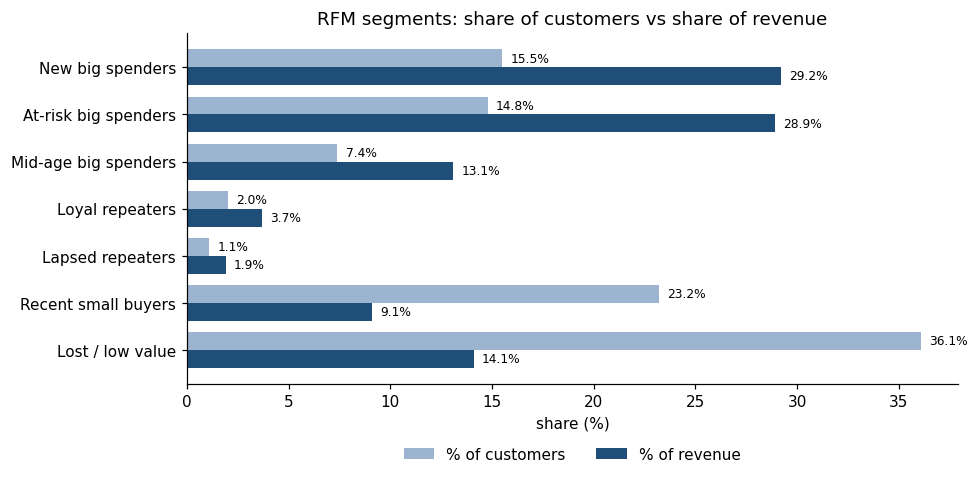

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = summary.iloc[::-1]
y = np.arange(len(s)); h = 0.38
ax.barh(y + h/2, s.pct_customers, h, label='% of customers', color='#9db4d0')
ax.barh(y - h/2, s.pct_revenue,   h, label='% of revenue',   color='#1f4e79')
ax.set_yticks(y); ax.set_yticklabels(s.index)
for i, (c, r) in enumerate(zip(s.pct_customers, s.pct_revenue)):
    ax.text(c + .4, i + h/2, f'{c:.1f}%', va='center', fontsize=8)
    ax.text(r + .4, i - h/2, f'{r:.1f}%', va='center', fontsize=8)
ax.set_xlabel('share (%)'); ax.set_title('RFM segments: share of customers vs share of revenue')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2); plt.tight_layout()
plt.savefig(FIG / 'rfm_segments.png'); plt.show()

### Reading the segments

*(Numbers in this section are measured. The suggested actions are hypotheses to test, not results.)*

| Segment | Definition | What the data shows | Suggested action to test |
|---|---|---|---|
| New big spenders | 1 order, top-40% spend, ordered in last ~6 months | 14.7k customers, 29% of revenue | Second-purchase nudge while the experience is fresh |
| At-risk big spenders | 1 order, top-40% spend, last order 9+ months ago | 14.0k customers, 29% of revenue | Win-back test with a holdout group |
| Mid-age big spenders | same, 6-9 months ago | 7.1k customers, 13% of revenue | Same as above, earlier |
| Loyal repeaters | 2+ orders, recent | 1.9k customers, 3.7% of revenue | Protect service quality; low priority for discounts |
| Lapsed repeaters | 2+ orders, not recent | 1.0k customers, 1.9% of revenue | Cheap reactivation message |
| Recent small buyers | 1 order, lower spend, recent | 22.0k customers, 9% of revenue | Cross-sell toward higher baskets |
| Lost / low value | 1 order, low spend, old | 34.3k customers, 14% of revenue | Do not invest |

The striking fact is how little the *repeat* segments matter: together they are 3% of customers and about 6% of revenue. Value sits in **one-time big spenders**, and the question is whether any of them can be brought back (section 3).

## 2. Cross-check with K-means

Do unsupervised clusters tell a different story from the hand-built rules? Features: log recency, log revenue, repeat flag (standardised).

In [4]:
X_all = StandardScaler().fit_transform(np.column_stack([
    np.log1p(seg.recency_days), np.log1p(seg.revenue), (seg.orders >= 2).astype(int)]))
rng = np.random.RandomState(0)
idx = rng.choice(len(X_all), 10_000, replace=False)       # silhouette on a sample (O(n^2))
rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=5, random_state=0).fit(X_all)
    rows.append((k, silhouette_score(X_all[idx], km.labels_[idx])))
print(pd.DataFrame(rows, columns=['k', 'silhouette']).round(3).to_string(index=False))

km2 = KMeans(2, n_init=5, random_state=0).fit(X_all)
print("\nk=2 clusters vs the repeat flag:")
print(pd.crosstab(km2.labels_, np.where(seg.orders >= 2, '2+ orders', '1 order'), rownames=['cluster']))

 k  silhouette
 2        0.72
 3        0.41
 4        0.39
 5        0.35
 6        0.36

k=2 clusters vs the repeat flag:


col_0    1 order  2+ orders
cluster                    
0          92096          0
1              0       2886


With the repeat flag included, the best silhouette (k=2) simply **recovers the repeat/non-repeat split**: the crosstab shows zero mixing. The clustering finds no structure beyond what the rule already encodes. Next, we cluster **one-time buyers only** (97% of the base), using recency and spend.

In [5]:
one = seg[seg.orders == 1].copy()
X1 = StandardScaler().fit_transform(np.column_stack([np.log1p(one.recency_days), np.log1p(one.revenue)]))
idx1 = rng.choice(len(X1), 10_000, replace=False)
rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=5, random_state=0).fit(X1)
    rows.append((k, silhouette_score(X1[idx1], km.labels_[idx1])))
sil = pd.DataFrame(rows, columns=['k', 'silhouette']).round(3)
print(sil.to_string(index=False))
best_k = int(sil.loc[sil.silhouette.idxmax(), 'k'])
print(f"\nBest k by silhouette: {best_k}")
one['cluster'] = KMeans(best_k, n_init=5, random_state=0).fit_predict(X1)
prof = one.groupby('cluster').agg(customers=('revenue', 'size'), median_recency_days=('recency_days', 'median'),
                                   median_spend=('revenue', 'median'), revenue=('revenue', 'sum'))
prof['pct_revenue'] = 100 * prof.revenue / prof.revenue.sum()
prof.round(1)

 k  silhouette
 2        0.40
 3        0.39
 4        0.34
 5        0.34
 6        0.35

Best k by silhouette: 2


,customers,median_recency_days,median_spend,revenue,pct_revenue
cluster,,,,,
0,70613,276.90,88.00,"9,789,931.60",76.80
1,21483,53.30,84.90,"2,954,000.70",23.20


With one-time buyers only, silhouette is highest at k=2 and the two clusters differ almost entirely by **recency** (median last order 277 vs 53 days ago), while median spend is nearly identical (R$88 vs R$85). Spend does not form natural groups here, so spend tiers (the quintile cuts above) are a business choice, not a statistical discovery. That is worth stating plainly in the report.

## 3. Retention: what predicts a second purchase?

Population: customers whose first order was on or before 2018-02-28, so everyone has a full 180-day follow-up window. **Repeat** = a second order placed more than 24 hours and at most 180 days after the first (this removes the 31% of second orders that happen within a day and look like split baskets rather than loyalty).

### 3.1 The retention curve

month_index        1      2      3      4      5      6
a             270.00 202.00 149.00 164.00 134.00 129.00
retention_pct   0.48   0.36   0.26   0.29   0.24   0.23


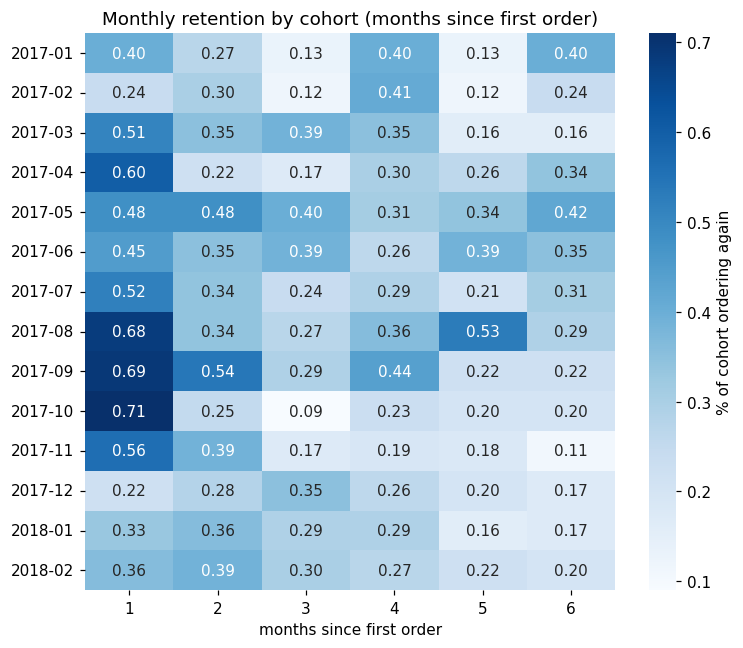

In [6]:
coh = pd.read_sql("SELECT cohort_month, cohort_size, month_index, active_customers, retention_pct::float AS retention_pct "
                  "FROM olist.vw_cohort_retention", engine)
coh['cohort_month'] = pd.to_datetime(coh['cohort_month'])
mature = coh[coh.cohort_month <= pd.Timestamp('2018-02-01')]    # cohorts with 6 months of follow-up
curve = mature[mature.month_index.between(1, 6)].groupby('month_index').agg(a=('active_customers', 'sum'))
base = mature[mature.month_index == 0].cohort_size.sum()
curve['retention_pct'] = 100 * curve.a / base
print(curve.round(2).T.to_string())

piv = (mature[mature.month_index.between(1, 6)]
       .assign(cohort=lambda d: d.cohort_month.dt.strftime('%Y-%m'))
       .pivot(index='cohort', columns='month_index', values='retention_pct'))
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(piv, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': '% of cohort ordering again'}, ax=ax)
ax.set_title('Monthly retention by cohort (months since first order)'); ax.set_xlabel('months since first order'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG / 'cohort_heatmap.png'); plt.show()

### 3.2 Does the first purchase category matter?

The earlier hypothesis was that low retention is structural because customers buy one-off categories. If so, repeat rates should differ sharply by category. Test it with confidence intervals and a chi-square test (categories with at least 1,000 first-time customers).

56,319 customers in population | overall repeat rate 1.89% (1,062 customers)

Chi-square across 18 categories: p = 2.2e-05


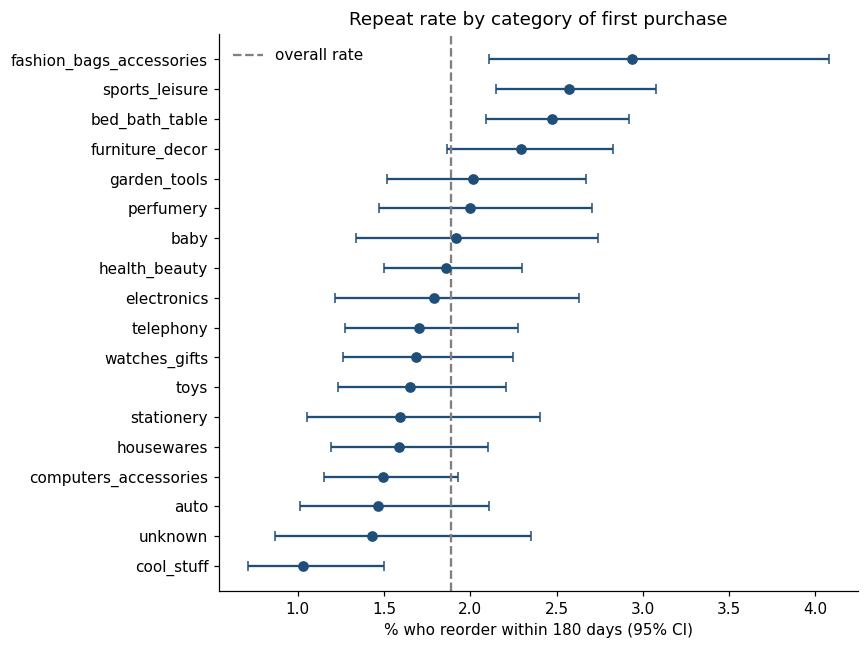

,count,sum,rate,lo,hi
first_category,,,,,
cool_stuff,2612,27,1.03,0.71,1.50
unknown,1047,15,1.43,0.87,2.35
auto,1913,28,1.46,1.01,2.11
bed_bath_table,5420,134,2.47,2.09,2.92
sports_leisure,4547,117,2.57,2.15,3.07
fashion_bags_accessories,1157,34,2.94,2.11,4.08


In [7]:
fo = sg.load_first_orders(engine)
print(f"{len(fo):,} customers in population | overall repeat rate {fo.repeat.mean():.2%} ({fo.repeat.sum():,} customers)\n")

c = fo.groupby('first_category').repeat.agg(['sum', 'count']).query('count >= 1000')
c['rate'] = 100 * c['sum'] / c['count']
c['lo'], c['hi'] = [100 * v for v in sg.wilson_ci(c['sum'], c['count'])]
c = c.sort_values('rate')
chi2, p, dof, _ = chi2_contingency(np.array([c['sum'], c['count'] - c['sum']]).T)
print(f"Chi-square across {len(c)} categories: p = {p:.1e}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(c.rate, range(len(c)), xerr=[c.rate - c.lo, c.hi - c.rate], fmt='o', color='#1f4e79', capsize=3)
ax.axvline(100 * fo.repeat.mean(), color='grey', ls='--', label='overall rate')
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index)
ax.set_xlabel('% who reorder within 180 days (95% CI)'); ax.set_title('Repeat rate by category of first purchase')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / 'repeat_by_category.png'); plt.show()
c[['count', 'sum', 'rate', 'lo', 'hi']].iloc[[0, 1, 2, -3, -2, -1]].round(2)

### 3.3 Does the first experience, or order value, matter?

In [8]:
def rate_table(col, order=None):
    t = fo.groupby(col, observed=True).repeat.agg(['sum', 'count'])
    t['rate_%'] = 100 * t['sum'] / t['count']
    t['ci_low'], t['ci_high'] = [100 * v for v in sg.wilson_ci(t['sum'], t['count'])]
    return t.round(2)

print("By first-order review score"); display(rate_table('first_review_score'))
print("By first delivery late?"); display(rate_table('first_is_late'))
fo['value_band'] = pd.cut(fo.first_order_value, [0, 50, 100, 200, np.inf], labels=['<R$50', 'R$50-100', 'R$100-200', 'R$200+'])
print("By first-order value"); display(rate_table('value_band'))

By first-order review score


,sum,count,rate_%,ci_low,ci_high
first_review_score,,,,,
1.00,95,6162,1.54,1.26,1.88
2.00,27,1829,1.48,1.02,2.14
3.00,88,4859,1.81,1.47,2.23
4.00,191,11085,1.72,1.50,1.98
5.00,656,31923,2.05,1.90,2.22


By first delivery late?


,sum,count,rate_%,ci_low,ci_high
first_is_late,,,,,
False,981,51012,1.92,1.81,2.05
True,64,4184,1.53,1.20,1.95


By first-order value


,sum,count,rate_%,ci_low,ci_high
value_band,,,,,
<R$50,323,17047,1.89,1.70,2.11
R$50-100,317,16520,1.92,1.72,2.14
R$100-200,260,14182,1.83,1.63,2.07
R$200+,162,8570,1.89,1.62,2.20


## 4. Conclusions

1. **Value is concentrated in one-time big spenders.** The top three segments (new, at-risk and mid-age big spenders) are 38% of customers and about 71% of revenue, yet all of them have bought only once. Repeat segments are about 3% of customers and 6% of revenue.
2. **Clustering adds nothing over the rules.** With the repeat flag included, K-means just rediscovers it. Among one-time buyers it separates only by recency (median 277 vs 53 days), not by spend, so the spend tiers are a business choice, not a natural grouping.
3. **Retention is very low everywhere.** The overall 180-day repeat rate is **1.89%**, and no category exceeds about 3%.
4. **The "one-off categories" hypothesis is not supported.** Categories do differ (chi-square p < 0.001), from 1.0% (cool_stuff) to 2.9% (fashion_bags_accessories), but the ranking does not follow a durable-vs-repeat-purchase logic: bed_bath_table, furniture_decor and sports_leisure are *above* average. The differences are real but small in absolute terms.
5. **Service quality has a modest effect, not a decisive one.** Customers whose first order got 5 stars reorder at about 2.05% against 1.54% after 1 star. The confidence intervals just touch (1.26-1.88% vs 1.90-2.22%), so the effect is real but small. A late first delivery gives 1.53% against 1.92%, with overlapping intervals (not conclusive). Order value shows no pattern (1.8-1.9% in every band), and payment type shows none either (`08_first_purchase_drivers.sql`, query 8.2).
6. **Implication.** Fixing delivery will improve reviews strongly (Phase 3) but is unlikely, on its own, to move retention much. A win-back test on the at-risk big-spender group (14k customers, R$3.9M in past revenue) with a **holdout control** is the cleanest way to learn whether *any* intervention can change the 2% baseline.

**Limitations:** the dataset has no marketing, price or competitor data, so these are associations in observational data. Repeat rates are low, so subgroup estimates have wide intervals. Customer identity relies on `customer_unique_id`, which may miss customers who register twice.